# Coefficient estimation for one AR(p) process

Choose **`p` in the settings cell**, then run the notebook from top to bottom. It generates one coefficient vector and one simulated path, finds a direction of small empirical width in dimension **k = p + 1**, prints that direction, and only then transforms it into coefficient estimates in a separate cell.

The search uses the same method as [ar3_minimum_width_k4.ipynb](ar3_minimum_width_k4.ipynb), section **Four-method coefficient comparison for known AR order**. The editable settings cell controls the number of starts, iteration budget, step scale, and geometric decay. Here, only the chosen embedding is optimized.

The reported minimizing direction is the **best direction found by the numerical search**. The notebook does not certify a global minimum.

In [25]:
import sys
from importlib import reload
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.spatial.distance import pdist
from threadpoolctl import threadpool_limits

AR_CODE_DIR = next(
    (
        candidate.resolve()
        for root in (Path.cwd(), *Path.cwd().parents)
        for candidate in (root / "Code" / "Code_AR_processes", root)
        if (candidate / "ar_tools/functions.py").is_file()
    ),
    None,
)
if AR_CODE_DIR is None:
    raise FileNotFoundError("Could not locate Code/Code_AR_processes.")
PROJECT_ROOT = AR_CODE_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Pick up shared optimizer updates when rerunning an existing notebook kernel.
from Code.Code_AR_processes.ar_tools import descent as descent_tools
reload(descent_tools)
from Code.Code_AR_processes.ar_tools.descent import projected_subgradient_empirical_width
from Code.Code_AR_processes.ar_tools.functions import (
    coefficients_from_minimizing_direction,
    is_stationary,
    jones_ar_coefficients,
    simulate_uniform_ar,
    sliding_window_point_cloud,
)

np.set_printoptions(precision=8, suppress=True)

## 1. Choose the process order and descent settings

Change `p` to the positive integer order you want. The coefficients are drawn automatically using the existing `jones_ar_coefficients` helper. The seeds make each run reproducible; change `coefficient_seed` or `process_seed` to generate a different process.

Implementation: [ar_tools/functions.py](ar_tools/functions.py), functions `jones_ar_coefficients` and `simulate_uniform_ar`.

In [26]:
p = 3                         # CHANGE THIS: desired AR order.
sample_size = 2_000            # Number of retained observations.
burnin = 1_000
innovation_half_width = 1.0    # Innovations are uniform on [-1, 1] by default.

coefficient_seed = 20260910
process_seed = 20260911
optimizer_seed = 20260912

number_of_starts = 12
optimization_iterations = 10_000
initial_step_scale = 0.2
geometric_decay = 0.997
improvement_tolerance = 1e-10

# Validate editable settings before simulating or optimizing.
for name, value, lower_bound in (
    ("p", p, 1),
    ("sample_size", sample_size, 1),
    ("burnin", burnin, 0),
    ("number_of_starts", number_of_starts, 1),
    ("optimization_iterations", optimization_iterations, 1),
):
    if (
        isinstance(value, (bool, np.bool_))
        or not isinstance(value, (int, np.integer))
        or value < lower_bound
    ):
        raise ValueError(f"{name} must be an integer at least {lower_bound}.")
if sample_size < p + 2:
    raise ValueError("sample_size must be at least p + 2 to form two embedding points.")
for name, value in (
    ("innovation_half_width", innovation_half_width),
    ("initial_step_scale", initial_step_scale),
):
    if not np.isfinite(value) or value <= 0:
        raise ValueError(f"{name} must be positive and finite.")
if not np.isfinite(geometric_decay) or not 0 < geometric_decay < 1:
    raise ValueError("geometric_decay must lie strictly between zero and one.")
if not np.isfinite(improvement_tolerance) or improvement_tolerance < 0:
    raise ValueError("improvement_tolerance must be finite and nonnegative.")

embedding_dimension = p + 1

## 2. Generate one AR(p) process

The simulation uses the sign convention

$$X_t=\sum_{j=1}^p\phi_j X_{t-j}+\varepsilon_t,$$

with zero intercept. The printed true coefficients are used for comparison after fitting. They are not passed to the direction optimizer.

Implementation: [ar_tools/functions.py](ar_tools/functions.py), functions `jones_ar_coefficients`, `is_stationary`, and `simulate_uniform_ar`.

In [27]:
true_phi = jones_ar_coefficients(p, rng=coefficient_seed)
stationary, companion_eigenvalues = is_stationary(true_phi)
if not stationary:
    raise RuntimeError("The generated coefficients did not pass the stationarity check.")

series = simulate_uniform_ar(
    true_phi,
    sample_size=sample_size,
    burnin=burnin,
    half_width=innovation_half_width,
    rng=process_seed,
)
if not np.all(np.isfinite(series)):
    raise RuntimeError("The simulated path contains nonfinite values.")

point_cloud = sliding_window_point_cloud(series, embedding_dimension)
point_cloud_diameter = float(pdist(point_cloud).max())
if not np.isfinite(point_cloud_diameter) or point_cloud_diameter <= 0:
    raise RuntimeError("Cannot normalize the step: the point-cloud diameter is invalid.")
initial_step = initial_step_scale / point_cloud_diameter

print(f"Generated one AR({p}) process")
print(f"True coefficients phi = {true_phi}")
print(f"Retained observations = {len(series)}; burn-in = {burnin}")
print(f"Embedding dimension k = {embedding_dimension}")
print(f"Point-cloud shape = {point_cloud.shape}")
print(f"Point-cloud diameter L_T = {point_cloud_diameter:.10f}")
print(f"Initial step eta_0 = {initial_step:.10g}")

Generated one AR(3) process
True coefficients phi = [-1.0201964  -0.40421235 -0.37447885]
Retained observations = 2000; burn-in = 1000
Embedding dimension k = 4
Point-cloud shape = (1997, 4)
Point-cloud diameter L_T = 36.5616732486
Initial step eta_0 = 0.005470209162


## 3. Find and output the minimizing direction

The newest-first embedding points are $Y_t=(X_t,X_{t-1},\ldots,X_{t-p})$. The search minimizes

$$\widehat w(u)=\max_t Y_t^\top u-\min_t Y_t^\top u,
\qquad \|u\|_2=1.$$

For each start, the shared optimizer uses

$$g_m=Y_{\max,m}-Y_{\min,m},\qquad
\xi_m=g_m-(u_m^\top g_m)u_m,$$

$$\eta_m=\frac{\texttt{initial\_step\_scale}}{L_T}
\texttt{geometric\_decay}^{\,m},\qquad
u_{m+1}=\frac{u_m-\eta_m\xi_m}{\|u_m-\eta_m\xi_m\|_2},\quad m=0,1,\ldots.$$

All starts are normalized Gaussian draws. Each start retains its best recorded direction, using the configured improvement tolerance. Each start stops after the configured number of consecutive iterations without sufficient improvement, or when its iteration budget is reached. Set `patience` in the descent call below; `improvement_tolerance` is in the settings cell. The smallest recorded width across starts is selected. Its sign is chosen so that $\widehat u_0\geq 0$, without consulting the true coefficients.

Implementation: [ar_tools/descent.py](ar_tools/descent.py), function `projected_subgradient_empirical_width`; embedding coordinate order: [ar_tools/functions.py](ar_tools/functions.py), function `sliding_window_point_cloud`.

In [28]:
# Refresh the optimizer here as well, so this cell can be rerun on its own.
from importlib import reload
from Code.Code_AR_processes.ar_tools import descent as descent_tools
reload(descent_tools)
from Code.Code_AR_processes.ar_tools.descent import projected_subgradient_empirical_width

initial_generator = np.random.default_rng(
    np.random.SeedSequence([optimizer_seed, 0, embedding_dimension, 20])
)
initial_directions = initial_generator.normal(
    size=(number_of_starts, embedding_dimension)
)
initial_directions /= np.linalg.norm(initial_directions, axis=1, keepdims=True)

optimization_start = perf_counter()
with threadpool_limits(limits=1):
    descent_results = [
        projected_subgradient_empirical_width(
            points=point_cloud,
            iterations=optimization_iterations,
            initial_step=initial_step,
            patience=200,
            improvement_tolerance=improvement_tolerance,
            rng=np.random.SeedSequence([
                optimizer_seed, 0, embedding_dimension, 21, start_index,
            ]),
            initial_direction=initial_direction,
            step_schedule="geometric",
            geometric_decay=geometric_decay,
        )
        for start_index, initial_direction in enumerate(initial_directions)
    ]
optimization_seconds = perf_counter() - optimization_start

start_widths = np.array([result["minimum_width"] for result in descent_results])
best_start_index = int(np.argmin(start_widths))
best_result = descent_results[best_start_index]
minimizing_direction = best_result["direction"].copy()
if minimizing_direction[0] < 0:
    minimizing_direction *= -1
minimum_width = float(best_result["minimum_width"])

if not np.all(np.isfinite(minimizing_direction)):
    raise RuntimeError("The selected direction contains nonfinite values.")
if not np.isclose(np.linalg.norm(minimizing_direction), 1.0):
    raise RuntimeError("The selected direction is not a unit vector.")
if not np.isclose(np.ptp(point_cloud @ minimizing_direction), minimum_width):
    raise RuntimeError("The selected direction does not reproduce the reported width.")

print(f"Best start = {best_start_index + 1} of {number_of_starts}")
print(f"Smallest empirical width found = {minimum_width:.10f}")
print("Minimizing unit direction u_hat (coordinates u_0, u_1, ..., u_p):")
print(minimizing_direction)
print(f"Norm of u_hat = {np.linalg.norm(minimizing_direction):.10f}")
print(f"First coordinate u_hat_0 = {minimizing_direction[0]:.10f}")
print(f"Optimization time = {optimization_seconds:.3f} seconds")

start_summary = pd.DataFrame({
    "start": np.arange(1, number_of_starts + 1),
    "best_width": start_widths,
    "iterations_evaluated": [len(result["width_history"]) for result in descent_results],
    "termination_reason": [result["termination_reason"] for result in descent_results],
    "selected": np.arange(number_of_starts) == best_start_index,
})
display(start_summary)

Best start = 3 of 12
Smallest empirical width found = 1.3055352045
Minimizing unit direction u_hat (coordinates u_0, u_1, ..., u_p):
[0.64637305 0.66248553 0.2788784  0.25601101]
Norm of u_hat = 1.0000000000
First coordinate u_hat_0 = 0.6463730489
Optimization time = 1.484 seconds


,start,best_width,iterations_evaluated,termination_reason,selected
0,1,1.323055,7351,patience,False
1,2,1.307361,7022,patience,False
2,3,1.305535,6537,patience,True
3,4,1.477141,7857,patience,False
4,5,1.852143,201,patience,False
5,6,1.307234,7030,patience,False
6,7,1.598704,7481,patience,False
7,8,1.760432,251,patience,False
8,9,1.307563,7168,patience,False
9,10,1.308488,7140,patience,False


## 3a. Inspect every start across iterations

Each panel shows one start: **blue is the current empirical width**, and **orange is the best width recorded so far**. The selected start is highlighted. The panel titles give the best width and the number of evaluated iterations.

The first figure shows the full run for every start. The second zooms into the **last 1,000 iterations** of each run, so late changes are visible. If a run has fewer than 1,000 iterations, its complete trace is shown in both figures. Each panel uses its own vertical scale.

These figures use the existing `descent_results`; running the plotting cell alone does not rerun descent. Both figures are displayed below and automatically saved as PDF and PNG under `outputs/pdfs/ar_single_process_coefficient_estimation/` and `outputs/images/ar_single_process_coefficient_estimation/`.

Trace implementation: [ar_tools/descent.py](ar_tools/descent.py), `projected_subgradient_empirical_width` (the `width_history` and `best_width_history` arrays).

All iterations: PDF saved to /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar_single_process_coefficient_estimation/descent_starts_all_iterations.pdf


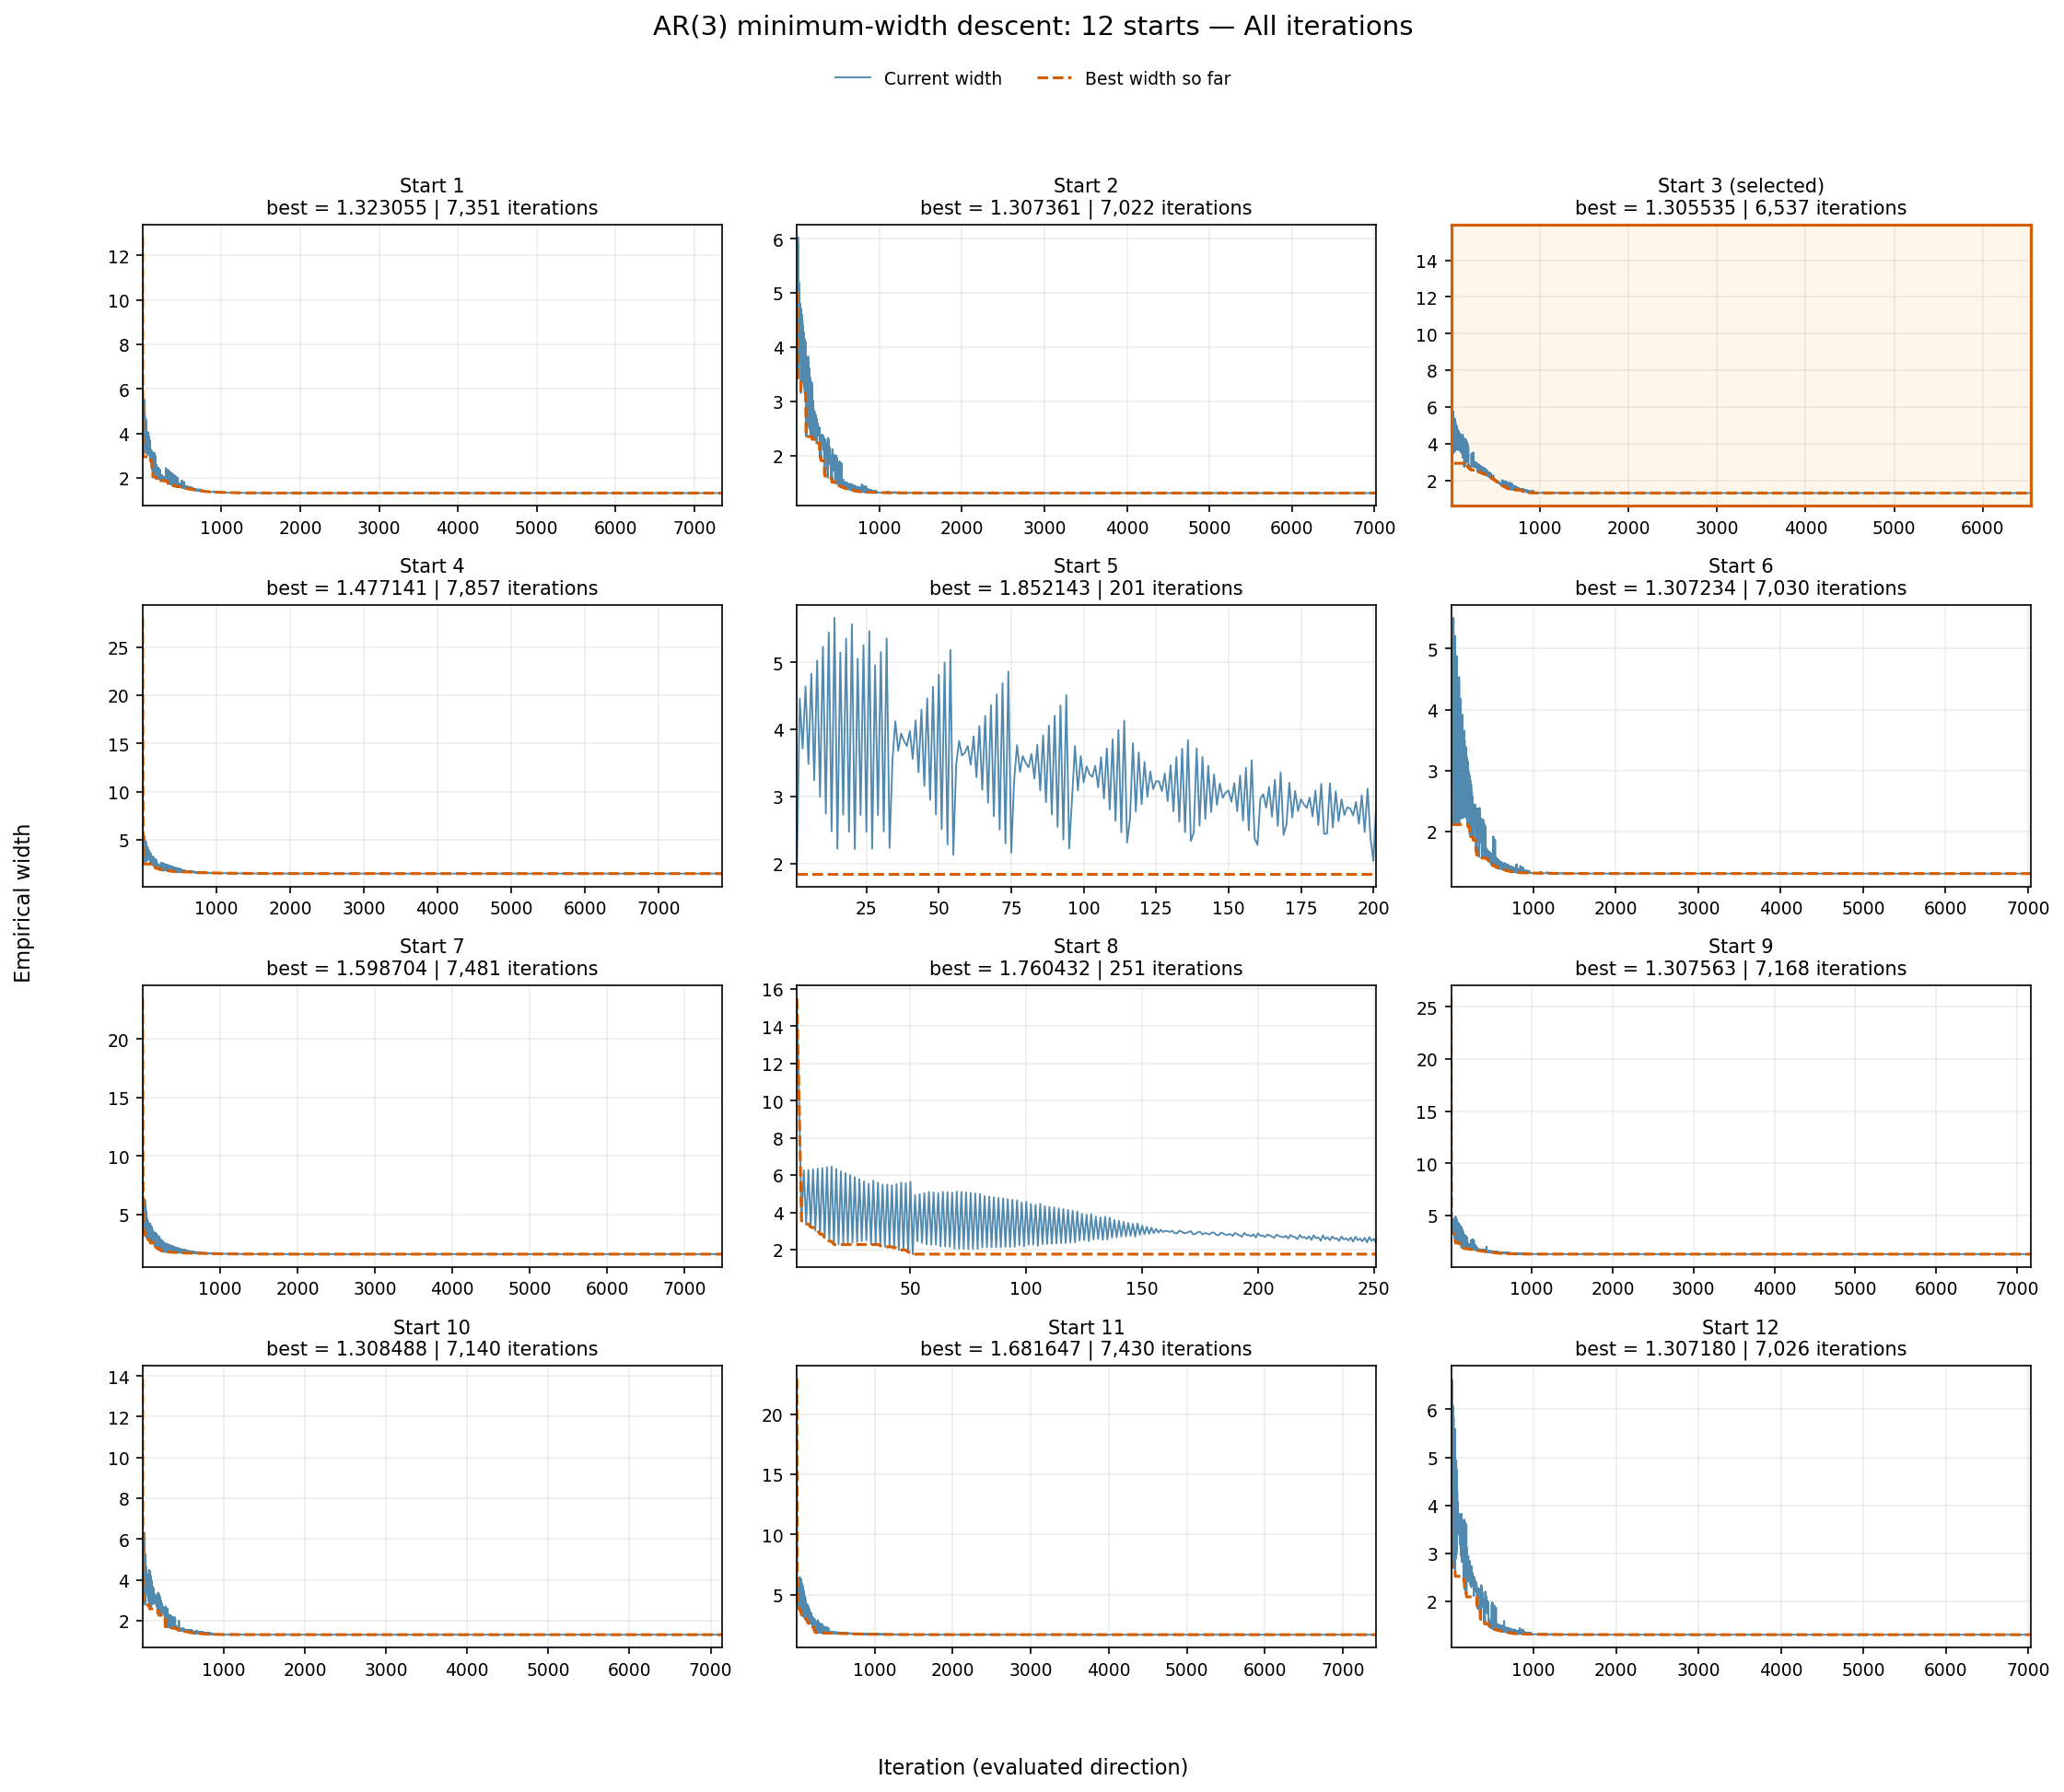

Last 1,000 iterations of each start: PDF saved to /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar_single_process_coefficient_estimation/descent_starts_last_1000_iterations.pdf


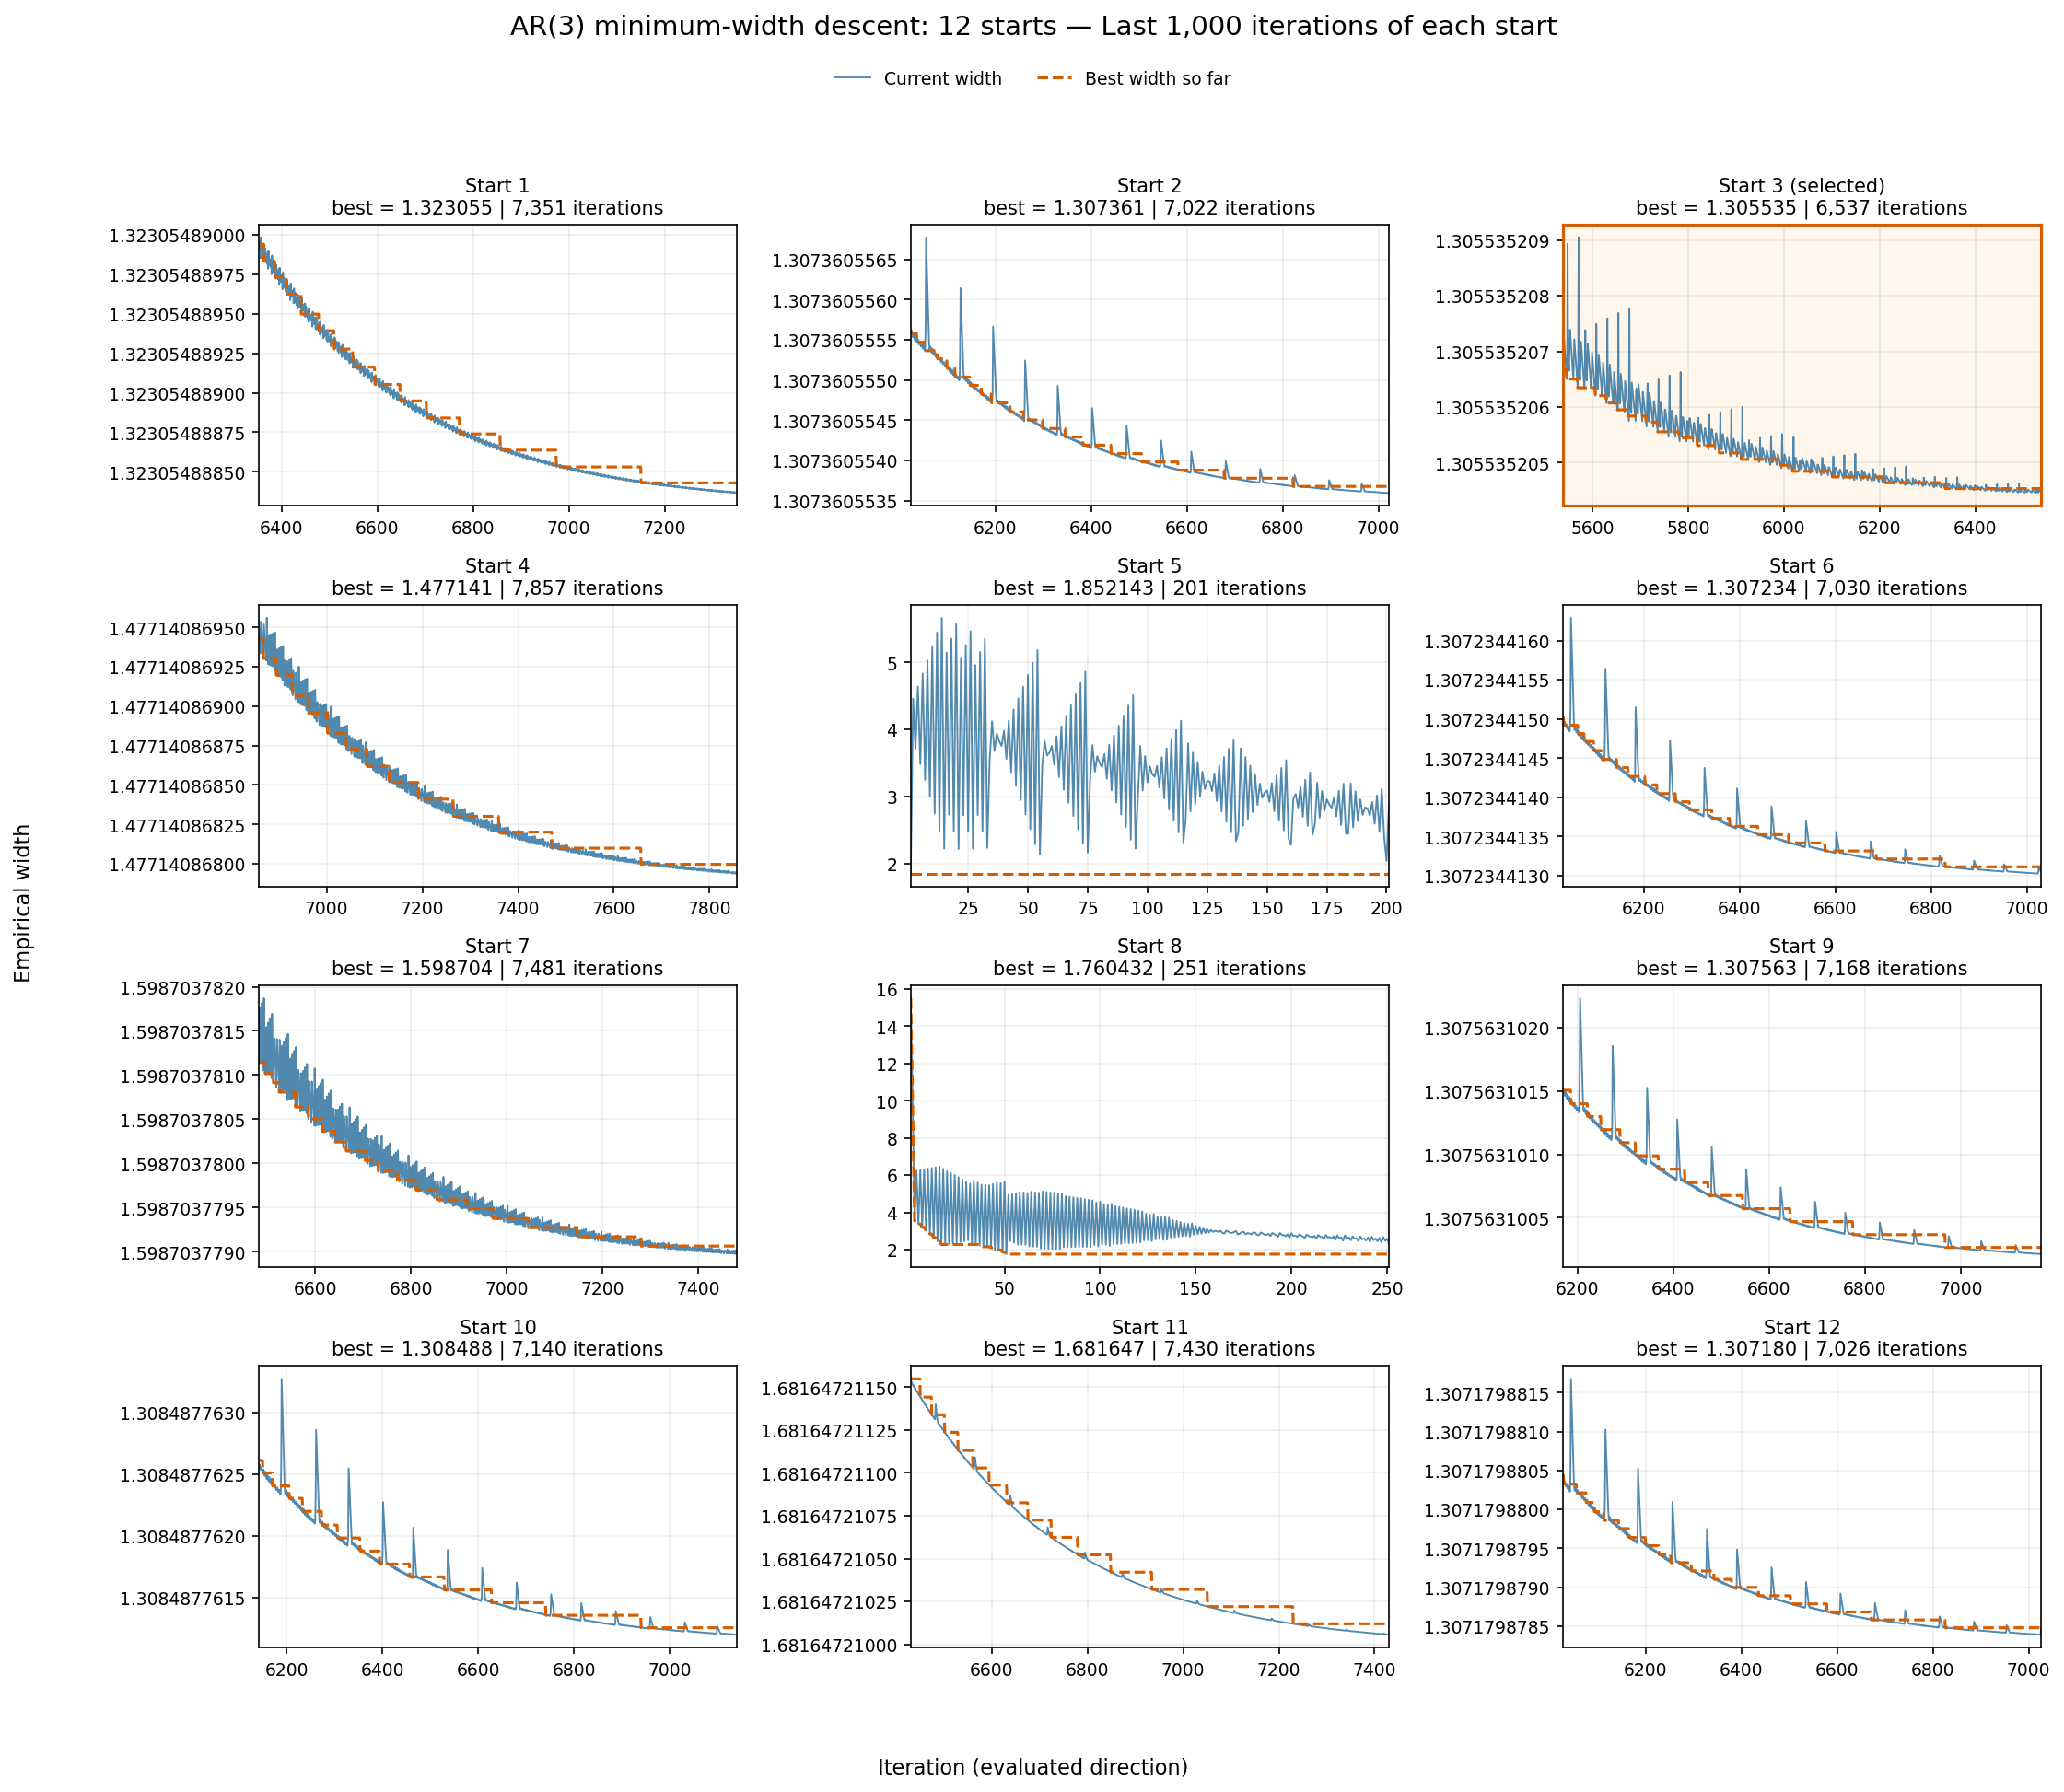

In [29]:
PDF_DIR = AR_CODE_DIR / "outputs" / "pdfs" / "ar_single_process_coefficient_estimation"
IMAGE_DIR = AR_CODE_DIR / "outputs" / "images" / "ar_single_process_coefficient_estimation"
PDF_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

plotted_start_count = len(descent_results)
plot_columns = min(3, plotted_start_count)
plot_rows = (plotted_start_count + plot_columns - 1) // plot_columns
iteration_plot_paths = []

for view_name, tail_iterations, view_title in (
    ("all_iterations", None, "All iterations"),
    ("last_1000_iterations", 1_000, "Last 1,000 iterations of each start"),
):
    with plt.rc_context({"font.size": 9, "pdf.fonttype": 42}):
        fig, axes = plt.subplots(
            plot_rows,
            plot_columns,
            figsize=(5.0 * plot_columns, 3.0 * plot_rows + 1.0),
            squeeze=False,
        )
        for start_index, (ax, result) in enumerate(zip(axes.flat, descent_results)):
            current_widths = np.asarray(result["width_history"])
            best_widths = np.asarray(result["best_width_history"])
            first_index = (
                0 if tail_iterations is None
                else max(0, len(current_widths) - tail_iterations)
            )
            shown_iterations = np.arange(first_index + 1, len(current_widths) + 1)
            ax.plot(
                shown_iterations,
                current_widths[first_index:],
                color="#3274A1",
                linewidth=0.9,
                alpha=0.85,
                label="Current width",
            )
            ax.plot(
                shown_iterations,
                best_widths[first_index:],
                color="#D55E00",
                linestyle="--",
                linewidth=1.5,
                label="Best width so far",
            )
            selected_label = " (selected)" if start_index == best_start_index else ""
            ax.set_title(
                f"Start {start_index + 1}{selected_label}\n"
                f"best = {result['minimum_width']:.6f} | {len(current_widths):,} iterations",
                fontsize=10,
            )
            if start_index == best_start_index:
                ax.set_facecolor("#fff6eb")
                for spine in ax.spines.values():
                    spine.set_color("#D55E00")
                    spine.set_linewidth(1.5)
            ax.set_xlim(
                shown_iterations[0],
                max(shown_iterations[-1], shown_iterations[0] + 1),
            )
            ax.ticklabel_format(axis="y", style="plain", useOffset=False)
            ax.grid(alpha=0.22)

        for ax in list(axes.flat)[plotted_start_count:]:
            ax.set_visible(False)
        legend_handles, legend_labels = axes.flat[0].get_legend_handles_labels()
        fig.suptitle(
            f"AR({p}) minimum-width descent: {plotted_start_count} starts — {view_title}",
            fontsize=14,
            y=0.995,
        )
        fig.legend(
            legend_handles,
            legend_labels,
            loc="upper center",
            bbox_to_anchor=(0.5, 0.972),
            ncol=2,
            frameon=False,
        )
        fig.supxlabel("Iteration (evaluated direction)", y=0.012)
        fig.supylabel("Empirical width", x=0.008)
        fig.tight_layout(rect=(0.025, 0.035, 1.0, 0.94))

        pdf_path = PDF_DIR / f"descent_starts_{view_name}.pdf"
        png_path = IMAGE_DIR / f"descent_starts_{view_name}.png"
        fig.savefig(pdf_path, bbox_inches="tight")
        fig.savefig(png_path, dpi=150, bbox_inches="tight")
        plt.close(fig)
        iteration_plot_paths.append({"pdf": pdf_path, "png": png_path})
        print(f"{view_title}: PDF saved to {pdf_path}")
        display(Image(filename=str(png_path)))

## 4. Transform the direction into coefficient estimates

Only this cell computes the coefficient estimate. The algebra used here is

$$u^\top Y_t=u_0\left(X_t-\sum_{j=1}^p
\left(-\frac{u_j}{u_0}\right)X_{t-j}\right),$$

so the coordinate transformation is

$$\boxed{\widehat\phi_j=-\frac{\widehat u_j}{\widehat u_0},
\qquad j=1,\ldots,p.}$$

The implementation below calls the shared transformation helper, which rejects a first coordinate numerically close to zero. The table shows each transformed coefficient alongside its true value.

Implementation: [ar_tools/functions.py](ar_tools/functions.py), function `coefficients_from_minimizing_direction`. The displayed algebra is a direct expansion of the newest-first inner product.

In [30]:
estimated_phi = coefficients_from_minimizing_direction(minimizing_direction)
if estimated_phi.shape != (p,) or not np.all(np.isfinite(estimated_phi)):
    raise RuntimeError("The coefficient transformation did not produce p finite estimates.")

coefficient_comparison = pd.DataFrame({
    "lag j": np.arange(1, p + 1),
    "u_hat_j": minimizing_direction[1:],
    "u_hat_0": minimizing_direction[0],
    "true_phi_j": true_phi,
    "estimated_phi_j": estimated_phi,
    "error": estimated_phi - true_phi,
    "absolute_error": np.abs(estimated_phi - true_phi),
})

print(f"Dividing the negated lag coordinates by u_hat_0 = {minimizing_direction[0]:.10f}")
print(f"Estimated coefficients phi_hat = {estimated_phi}")
display(coefficient_comparison)
print(f"Coefficient L1 error = {np.abs(estimated_phi - true_phi).sum():.10f}")
print(f"Mean squared coefficient error = {np.mean((estimated_phi - true_phi) ** 2):.10f}")

Dividing the negated lag coordinates by u_hat_0 = 0.6463730489
Estimated coefficients phi_hat = [-1.02492753 -0.43145116 -0.39607314]


,lag j,u_hat_j,u_hat_0,true_phi_j,estimated_phi_j,error,absolute_error
0,1,0.662486,0.646373,-1.020196,-1.024928,-0.004731,0.004731
1,2,0.278878,0.646373,-0.404212,-0.431451,-0.027239,0.027239
2,3,0.256011,0.646373,-0.374479,-0.396073,-0.021594,0.021594


Coefficient L1 error = 0.0535642504
Mean squared coefficient error = 0.0004102168
